Loading the libraries and dataset

In [8]:
import numpy as np 
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt
import warnings 
warnings.filterwarnings("ignore")

df=pd.read_csv("IPL.csv")

print(df.head())

   match_id           date                                         venue  \
0         1  March 26,2022                      Wankhede Stadium, Mumbai   
1         2  March 27,2022                     Brabourne Stadium, Mumbai   
2         3  March 27,2022            Dr DY Patil Sports Academy, Mumbai   
3         4  March 28,2022                      Wankhede Stadium, Mumbai   
4         5  March 29,2022  Maharashtra Cricket Association Stadium,Pune   

       team1      team2  stage toss_winner toss_decision  first_ings_score  \
0    Chennai    Kolkata  Group     Kolkata         Field               131   
1      Delhi     Mumbai  Group       Delhi         Field               177   
2   Banglore     Punjab  Group      Punjab         Field               205   
3    Gujarat    Lucknow  Group     Gujarat         Field               158   
4  Hyderabad  Rajasthan  Group   Hyderabad         Field               210   

   first_ings_wkts  second_ings_score  second_ings_wkts match_winner   won

Basic Info 

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 74 entries, 0 to 73
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   match_id             74 non-null     int64
 1   date                 74 non-null     str  
 2   venue                74 non-null     str  
 3   team1                74 non-null     str  
 4   team2                74 non-null     str  
 5   stage                74 non-null     str  
 6   toss_winner          74 non-null     str  
 7   toss_decision        74 non-null     str  
 8   first_ings_score     74 non-null     int64
 9   first_ings_wkts      74 non-null     int64
 10  second_ings_score    74 non-null     int64
 11  second_ings_wkts     74 non-null     int64
 12  match_winner         74 non-null     str  
 13  won_by               74 non-null     str  
 14  margin               74 non-null     int64
 15  player_of_the_match  74 non-null     str  
 16  top_scorer           74 non-null     st

Check the size of rows and cols of dataset

In [6]:
print(f" Your rows are {df.shape[0]} and columns are {df.shape[1]}")

 Your rows are 74 and columns are 20


Now let's See how many columns have null values in total 

In [7]:
df.isnull().sum()

match_id               0
date                   0
venue                  0
team1                  0
team2                  0
stage                  0
toss_winner            0
toss_decision          0
first_ings_score       0
first_ings_wkts        0
second_ings_score      0
second_ings_wkts       0
match_winner           0
won_by                 0
margin                 0
player_of_the_match    0
top_scorer             0
highscore              0
best_bowling           0
best_bowling_figure    0
dtype: int64

Now Here Come some basic Questions

1. Which team won the most matches 

Text(0.5, 1.0, 'Most math wins by team')

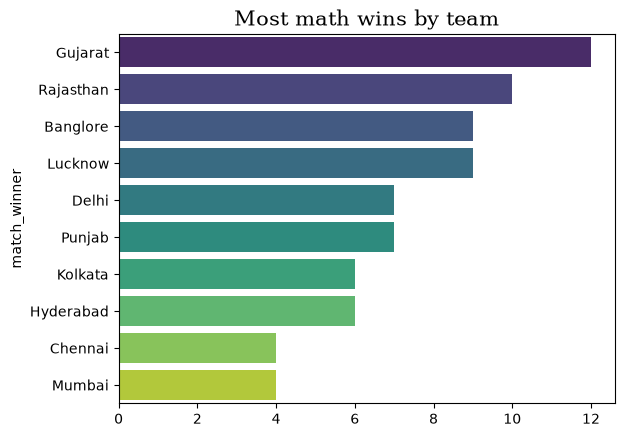

In [21]:
match_wins = df['match_winner'].value_counts()

sns.barplot(y=match_wins.index,x=match_wins.values,palette="viridis",)

plt.title("Most math wins by team",fontsize=15,fontfamily="serif")



2. Toss Decision Trends

Text(0.5, 1.0, 'Toss Decision trends')

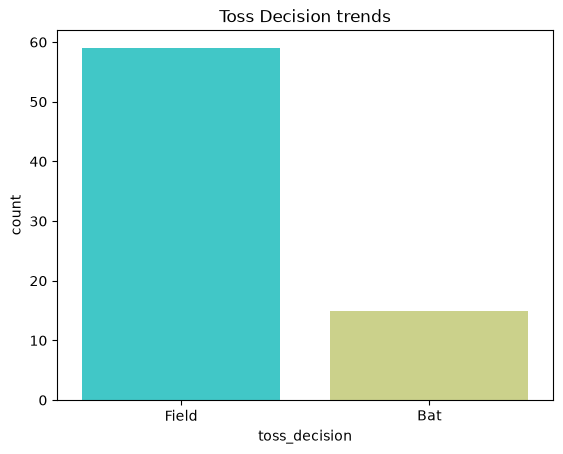

In [22]:
sns.countplot(x=df['toss_decision'],palette='rainbow')

plt.title("Toss Decision trends")

3.Toss Winner vs Match Winner 

In [ ]:
count=df[df['toss_winner']==df['match_winner']]['match_id'].count() # Every match id is differed 
percentage=(count*100)/df.shape[0]
percentage.round(2)


np.float64(48.65)

4.How to teams win ? ( Runs vs Wicktes)

Text(0.5, 1.0, 'Won By')

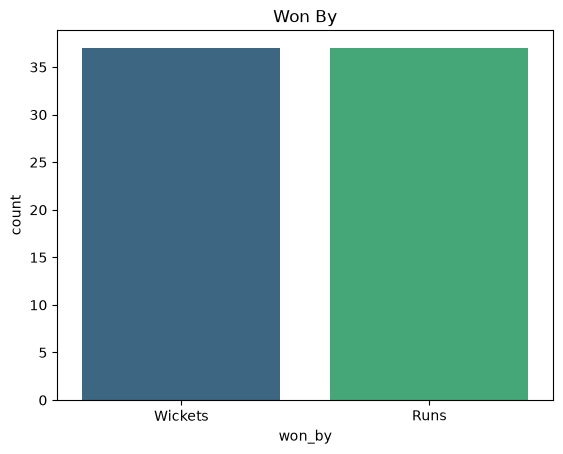

In [25]:
sns.countplot(x=df['won_by'],palette='viridis')

plt.title("Won By")

Key Player Performances 

1. Most "POM" Awards

Text(0, 0.5, 'Player Name')

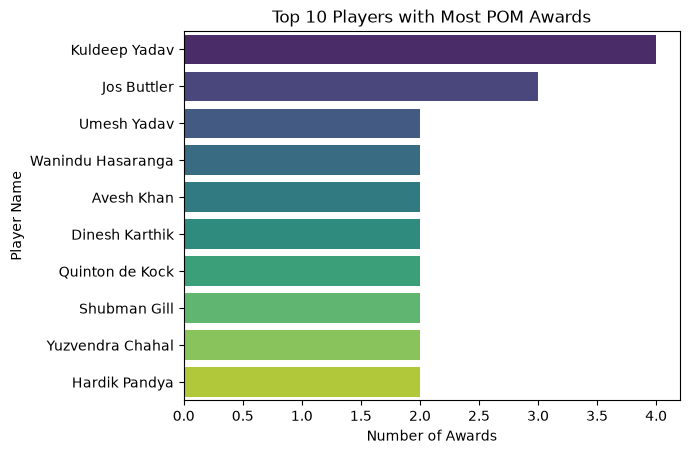

In [29]:
count=df['player_of_the_match'].value_counts().head(10)

sns.barplot(x=count.values, y=count.index, palette='viridis')
plt.title("Top 10 Players with Most POM Awards")
plt.xlabel("Number of Awards")
plt.ylabel("Player Name")

2.Top Scorers

Text(0.5, 1.0, 'Top 10 Scorers')

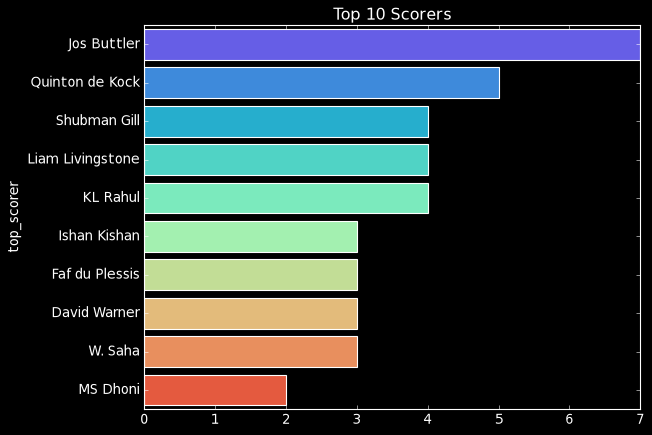

In [34]:
count=df['top_scorer'].value_counts().head(10)
plt.style.use('dark_background')
sns.barplot(x=count.values,y=count.index,palette='rainbow')

plt.title("Top 10 Scorers")

In [39]:
high=df.groupby('top_scorer')['highscore'].sum().sort_values(ascending=False).head(3)

high

top_scorer
Jos Buttler        651
Quinton de Kock    377
KL Rahul           351
Name: highscore, dtype: int64

<Axes: ylabel='top_scorer'>

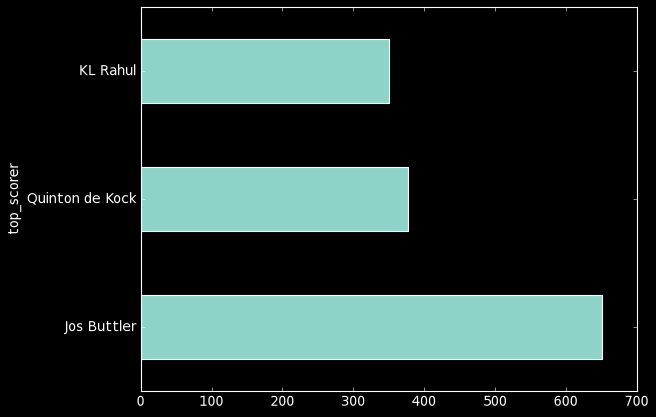

In [36]:
high.plot(kind='barh')


10 Best Bowling Figures

In [41]:
df['highest_wickets']=df['best_bowling_figure'].apply(lambda x : x.split('--')[0])
df['highest_wickets']=df['highest_wickets'].astype(int)

top_bowlers=df.groupby('best_bowling')['highest_wickets'].sum().sort_values(ascending=False).head(5)

top_bowlers

best_bowling
Yuzvendra Chahal    17
Jasprit Bumrah      11
Kuldeep Yadav       11
Rashid Khan         11
Josh Hazlewood      10
Name: highest_wickets, dtype: int64

<Axes: ylabel='best_bowling'>

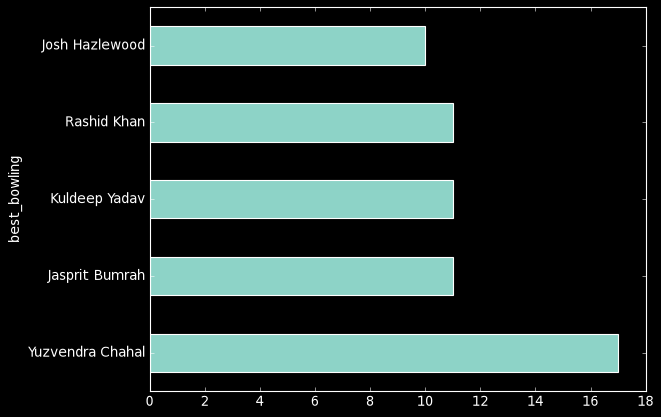

In [46]:
top_bowlers.plot(kind='barh') # fir vetical kind='bar'

Venue Analysis 

Most Matches playe by Venue 

In [47]:
df.head()

,match_id,date,venue,team1,team2,stage,toss_winner,toss_decision,first_ings_score,first_ings_wkts,...,second_ings_wkts,match_winner,won_by,margin,player_of_the_match,top_scorer,highscore,best_bowling,best_bowling_figure,highest_wickets
0,1,"March 26,2022","Wankhede Stadium, Mumbai",Chennai,Kolkata,Group,Kolkata,Field,131,5,...,4,Kolkata,Wickets,6,Umesh Yadav,MS Dhoni,50,Dwayne Bravo,3--20,3
1,2,"March 27,2022","Brabourne Stadium, Mumbai",Delhi,Mumbai,Group,Delhi,Field,177,5,...,6,Delhi,Wickets,4,Kuldeep Yadav,Ishan Kishan,81,Kuldeep Yadav,3--18,3
2,3,"March 27,2022","Dr DY Patil Sports Academy, Mumbai",Banglore,Punjab,Group,Punjab,Field,205,2,...,5,Punjab,Wickets,5,Odean Smith,Faf du Plessis,88,Mohammed Siraj,2--59,2
3,4,"March 28,2022","Wankhede Stadium, Mumbai",Gujarat,Lucknow,Group,Gujarat,Field,158,6,...,5,Gujarat,Wickets,5,Mohammed Shami,Deepak Hooda,55,Mohammed Shami,3--25,3
4,5,"March 29,2022","Maharashtra Cricket Association Stadium,Pune",Hyderabad,Rajasthan,Group,Hyderabad,Field,210,6,...,7,Rajasthan,Runs,61,Sanju Samson,Aiden Markram,57,Yuzvendra Chahal,3--22,3


In [48]:
count=df['venue'].value_counts()
count

venue
Wankhede Stadium, Mumbai                        21
Dr DY Patil Sports Academy, Mumbai              20
Brabourne Stadium, Mumbai                       16
Maharashtra Cricket Association Stadium,Pune    13
Eden Gardens, Kolkata                            2
Narendra Modi Stadium, Ahmedabad                 2
Name: count, dtype: int64

Text(0.5, 1.0, 'Most Matches played by Venue')

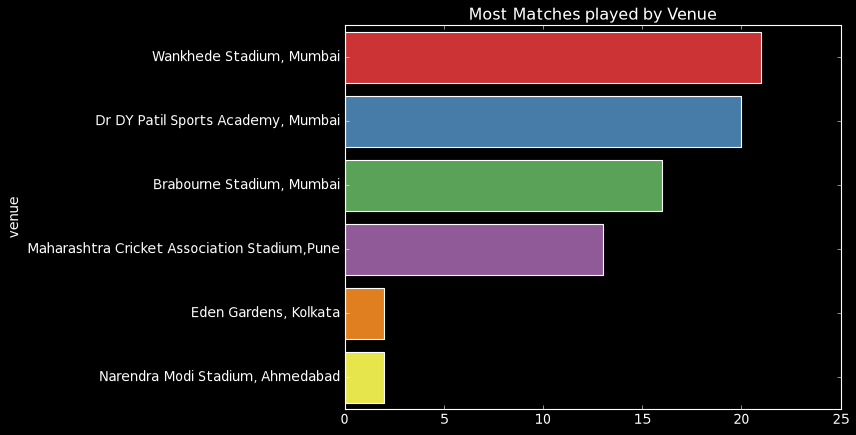

In [54]:
sns.barplot(x=count.values,y=count.index,palette='Set1')

plt.title("Most Matches played by Venue")

Custom Questions & InSights 

1. Who won the highest margin by runs 

In [56]:
ans=df[df['won_by']=='Runs'].sort_values(by='margin',ascending=False).head(1)[['match_winner','margin']]
ans


,match_winner,margin
54,Chennai,91


2.Which player had Highest Indivisual Score 

In [ ]:
df[df['highscore'] == df['highscore'].max()][['top_scorer','highscore']]
# df[df['highscore'] == df['highscore'].sort_values(ascending=False).head(1).values[0]][['top_scorer','highscore']]

,top_scorer,highscore
65,Quinton de Kock,140


3.Which Bowler has the Best Bowling Figures

In [ ]:
# highest_wicktes , if equal lesser runs conceived bowler 
df[df['highest_wickets'] == df['highest_wickets'].max()][['best_bowling','best_bowling_figure']]

,best_bowling,best_bowling_figure
29,Yuzvendra Chahal,5--40
39,Umran Malik,5--25
53,Wanindu Hasaranga,5--18
55,Jasprit Bumrah,5--10


In [ ]:
# End of Project 